# BogotáSafe — Pipeline Completo de Ciencia de Datos, Exploración de Hiperparámetros y Selección de Modelos

Este cuaderno implementa de forma reproducible el flujo completo de **limpieza, ingeniería de características, entrenamiento comparativo, exploración sistemática de hiperparámetros, selección formal de modelos finales y destilación a artefacto JSON** (`modelo_seguridad_bogota.json`) para la aplicación móvil **BogotáSafe** (Android / Kotlin / Jetpack Compose).

| Dimensión del Riesgo | Fuente Oficial | Tarea de ML | Modelos Evaluados | Modelo Final Seleccionado |
| :--- | :--- | :--- | :--- | :--- |
| **1. Espacial** | IDECA (`IRSCAT.gpkg`) | Clustering no supervisado | K-Means, Jerárquico Aglomerativo, GMM, DBSCAN | **K-Means ($k=7$, `k-means++`)** |
| **2. Demográfica** | Medicina Legal (`Violencia_interpersonal_Colombia.csv`) | Clasificación probabilística (Vía Pública) | CategoricalNB, Regresión Logística, Árbol de Decisión, Random Forest | **Categorical Naive Bayes + Razón de Verosimilitud (Censo DANE)** |
| **3. Temporal** | Secretaría de Seguridad / NUSE 123 (`incidente-reportado-bogota-d-c.csv`) | Regresión de conteos (Mes-Día-Hora) | GLM Poisson, GLM Tweedie, Ridge, Random Forest, HistGradientBoosting | **GLM Regresión de Poisson (con $\alpha$ óptimo por CV)** |

In [21]:
!pip install -q geopandas fiona pyogrio scikit-learn matplotlib seaborn scipy
!pip install -q pyxlsb

/opt/conda/lib/python3.13/pty.py:95: DeprecationWarning: This process (pid=49) is multi-threaded, use of forkpty() may lead to deadlocks in the child.
  pid, fd = os.forkpty()


In [2]:
import warnings
warnings.filterwarnings("ignore")

import json
import math
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import pyproj
from scipy import stats
from IPython.display import display

# Configuración visual y reproducibilidad global
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.rcParams['figure.dpi'] = 100
sns.set_style("whitegrid")

print("Entorno inicializado correctamente. Semilla global:", RANDOM_STATE)

Entorno inicializado correctamente. Semilla global: 42


---
## 1. Dimensión Espacial: 
### 1.1 Contexto y Preprocesamiento Geográfico
Se utiliza la información catastral de Bogotá (IRSCAT.gpkg), proporcionada por IDECA. Primero, se ajustan los mapas a un sistema de medidas oficial para Bogotá, lo que permite calcular con precisión el área de cada sector en km². Luego, se selecciona únicamente la zona urbana, excluyendo Sumapaz y las áreas rurales más alejadas.

Para evitar sesgos por tamaño geográfico del sector catastral, el agrupamiento se realiza sobre **densidades delictivas** (hurtos, homicidios y lesiones por $\text{km}^2$ en la ventana 2023–2025) junto con el volumen total de delitos.

In [3]:
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# 1. Cargar capa georreferenciada y reproyectar a EPSG:3116
path_gpkg = "Data/IRSCAT.gpkg"
gdf_raw = gpd.read_file(path_gpkg)
gdf_metric = gdf_raw.to_crs(epsg=3116)

# Filtrar casco urbano de Bogotá
centroides_y = gdf_metric.geometry.centroid.y
gdf_urbano = gdf_metric[centroides_y > 990000].copy()
print(f"Sectores catastrales urbanos procesados: {len(gdf_urbano):,}")

# 2. Extracción de variables delictivas recientes (2023-2025)
cols_hom = [c for c in gdf_urbano.columns if c.startswith('CMH') and any(c.endswith(y) for y in ['23CONT', '24CONT', '25CONT']) and not c.startswith('CMHC')]
cols_hur = [c for c in gdf_urbano.columns if c.startswith('CMR') and any(c.endswith(y) for y in ['23CONT', '24CONT', '25CONT'])]
cols_les = [c for c in gdf_urbano.columns if c.startswith('CMN') and any(c.endswith(y) for y in ['23CONT', '24CONT', '25CONT'])]

gdf_urbano['homicidios_totales'] = gdf_urbano[cols_hom].sum(axis=1)
gdf_urbano['hurtos_totales'] = gdf_urbano[cols_hur].sum(axis=1)
gdf_urbano['lesiones_totales'] = gdf_urbano[cols_les].sum(axis=1)
gdf_urbano['delitos_totales'] = (
    gdf_urbano['homicidios_totales'] +
    gdf_urbano['hurtos_totales'] +
    gdf_urbano['lesiones_totales']
)

# Normalización por área (densidad por km²)
gdf_urbano['area_km2'] = (gdf_urbano.geometry.area / 1e6).replace(0, 0.001)
gdf_urbano['densidad_hurtos'] = gdf_urbano['hurtos_totales'] / gdf_urbano['area_km2']
gdf_urbano['densidad_homicidios'] = gdf_urbano['homicidios_totales'] / gdf_urbano['area_km2']
gdf_urbano['densidad_lesiones'] = gdf_urbano['lesiones_totales'] / gdf_urbano['area_km2']

features_delictivas = ['densidad_hurtos', 'densidad_homicidios', 'densidad_lesiones', 'delitos_totales']
X_raw_esp = gdf_urbano[features_delictivas].fillna(0).values

# Escalamiento estándar y robusto para análisis de sensibilidad
scaler_std = StandardScaler()
X_delictivo = scaler_std.fit_transform(X_raw_esp)

scaler_rob = RobustScaler()
X_delictivo_rob = scaler_rob.fit_transform(X_raw_esp)

print("Resumen estadístico de las variables espaciales de entrada:")
display(gdf_urbano[features_delictivas].describe().round(2))

Sectores catastrales urbanos procesados: 1,049
Resumen estadístico de las variables espaciales de entrada:


,densidad_hurtos,densidad_homicidios,densidad_lesiones,delitos_totales
count,1049.00,1049.00,1049.00,1049.00
mean,2821.94,824.45,480.27,1207.31
std,2380.84,662.86,561.54,1008.78
min,0.00,0.00,0.00,0.00
25%,1006.19,357.35,124.24,371.00
50%,2375.63,787.24,346.65,1047.00
75%,4114.47,1175.95,651.78,1781.00
max,16246.88,9790.36,6963.17,5659.00


### 1.2 Exploración de Hiperparámetros y Comparación de Algoritmos de Clustering
Para seleccionar rigurosamente el modelo espacial, evaluamos **cuatro familias de algoritmos no supervisados** y sus respectivos hiperparámetros:
1. **K-Means:** Exploración de $k \in [2, 10]$, inicialización (`k-means++` vs. `random`) y sensibilidad al escalador (`StandardScaler` vs. `RobustScaler`).
2. **Clustering Jerárquico Aglomerativo (`AgglomerativeClustering`):** Exploración de $k \in [2, 10]$ y criterio de enlace (`ward`, `complete`, `average`).
3. **Modelos de Mezcla Gaussiana (`GaussianMixture`):** Exploración de componentes $k \in [2, 10]$ y estructura de covarianza (`full`, `tied`, `diag`), evaluando BIC además de Silhouette y Davies-Bouldin.
4. **DBSCAN:** Exploración de `eps` $\in [0.3, 0.5, 0.8, 1.0, 1.5]$ y `min_samples` $\in [5, 10, 20]$ para evaluar el comportamiento basado en densidad y la proporción de sectores etiquetados como ruido (`-1`).

--- 1) Exploración de k en K-Means (init='k-means++') ---


,k,Inercia,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2,2442.6,0.4076,0.9942,751.6
1,3,1911.8,0.3536,1.1384,624.9
2,4,1663.7,0.3290,1.3003,530.2
3,5,1483.1,0.3310,1.2472,477.4
4,6,1309.6,0.3259,1.1390,459.8
5,7,1160.9,0.3244,0.9891,454.0
6,8,1067.7,0.3209,1.0046,435.7
7,9,979.6,0.3103,1.0919,426.9
8,10,903.3,0.3129,1.0890,420.8


Sensibilidad RobustScaler en K-Means (k=7): Silhouette=0.3318, Davies-Bouldin=1.1937

--- 2) Tabla Comparativa Multi-Algoritmo (Dimensión Espacial) ---


,Familia de Modelo,Mejor Configuración,Clústeres,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑),% Sin Asignar (Ruido),Adecuación App Offline
0,K-Means (Seleccionado),"k=7, init=k-means++",7,0.3244,0.9891,454.0,0.00,"Óptima: cobertura 100%, centroides ordenables ..."
1,Agglomerative (Ward),"k=7, linkage=ward",7,0.2897,1.2454,374.0,0.00,Media: mayor solapamiento intra-clúster (peor ...
2,Gaussian Mixture (GMM),"k=7, cov=tied",7,0.2860,1.2136,156.5,0.00,Media: mayor complejidad paramétrica sin super...
3,DBSCAN,"eps=0.3, min_samples=10",3,0.4640,0.6778,238.3,61.96,Baja: deja sectores críticos como ruido (-1) s...


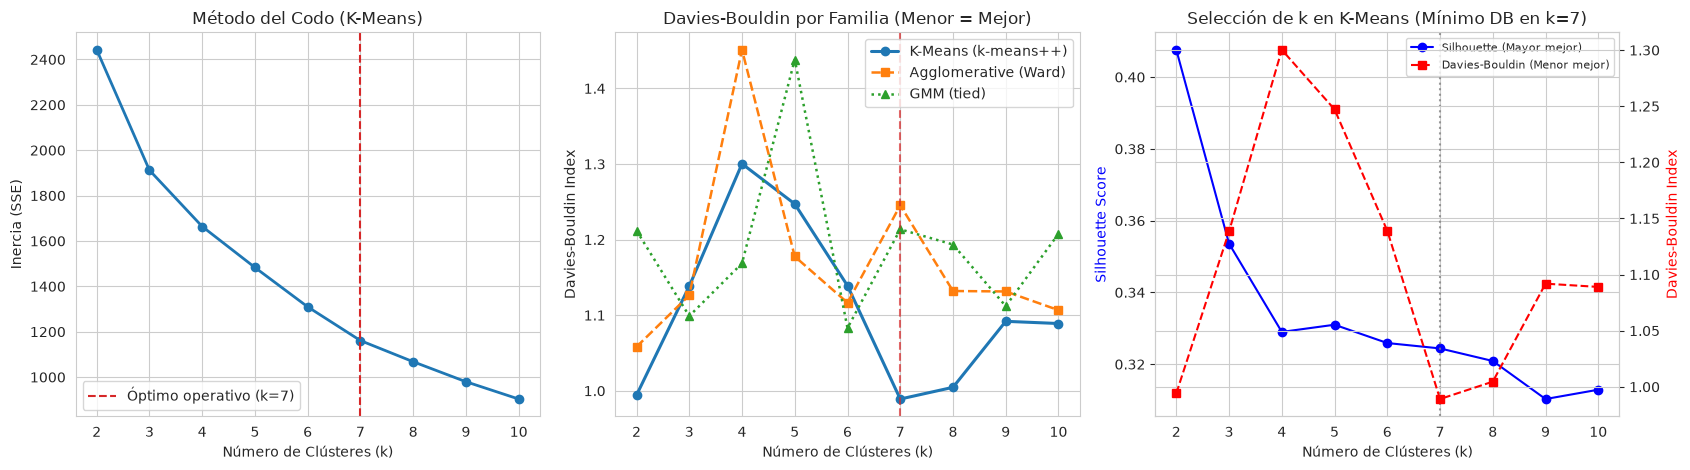

In [11]:
# --- A) Exploración exhaustiva de K-Means (k=2..10, init, escalador) ---
eval_kmeans = []
for k in range(2, 11):
    for init_m in ['k-means++', 'random']:
        km = KMeans(n_clusters=k, init=init_m, n_init=15, random_state=RANDOM_STATE)
        labels = km.fit_predict(X_delictivo)
        eval_kmeans.append({
            'Algoritmo': 'K-Means',
            'Escalador': 'StandardScaler',
            'k': k,
            'Hiperparámetros': f"k={k}, init={init_m}",
            'Inercia': round(km.inertia_, 1),
            'Silhouette': round(silhouette_score(X_delictivo, labels), 4),
            'Davies-Bouldin': round(davies_bouldin_score(X_delictivo, labels), 4),
            'Calinski-Harabasz': round(calinski_harabasz_score(X_delictivo, labels), 1),
            '% Ruido': 0.0
        })

df_eval_km = pd.DataFrame(eval_kmeans)
df_eval_k = df_eval_km[df_eval_km['Hiperparámetros'].str.contains('k-means++', regex=False)].reset_index(drop=True)

# Sensibilidad a RobustScaler en k=7
km_rob7 = KMeans(n_clusters=7, init='k-means++', n_init=15, random_state=RANDOM_STATE)
labels_rob7 = km_rob7.fit_predict(X_delictivo_rob)
sil_rob7 = round(silhouette_score(X_delictivo_rob, labels_rob7), 4)
db_rob7 = round(davies_bouldin_score(X_delictivo_rob, labels_rob7), 4)

# --- B) Exploración de Clustering Jerárquico Aglomerativo ---
eval_agg = []
for k in range(2, 11):
    for link in ['ward', 'complete', 'average']:
        agg = AgglomerativeClustering(n_clusters=k, linkage=link)
        labels = agg.fit_predict(X_delictivo)
        eval_agg.append({
            'Algoritmo': 'Agglomerative',
            'Escalador': 'StandardScaler',
            'k': k,
            'Hiperparámetros': f"k={k}, linkage={link}",
            'Inercia': np.nan,
            'Silhouette': round(silhouette_score(X_delictivo, labels), 4),
            'Davies-Bouldin': round(davies_bouldin_score(X_delictivo, labels), 4),
            'Calinski-Harabasz': round(calinski_harabasz_score(X_delictivo, labels), 1),
            '% Ruido': 0.0
        })
df_eval_agg = pd.DataFrame(eval_agg)

# --- C) Exploración de Gaussian Mixture Models (GMM) ---
eval_gmm = []
for k in range(2, 11):
    for cov in ['full', 'tied', 'diag']:
        gmm = GaussianMixture(n_components=k, covariance_type=cov, n_init=5, random_state=RANDOM_STATE)
        labels = gmm.fit_predict(X_delictivo)
        eval_gmm.append({
            'Algoritmo': 'GMM',
            'Escalador': 'StandardScaler',
            'k': k,
            'Hiperparámetros': f"k={k}, cov={cov}",
            'BIC': round(gmm.bic(X_delictivo), 1),
            'Silhouette': round(silhouette_score(X_delictivo, labels), 4),
            'Davies-Bouldin': round(davies_bouldin_score(X_delictivo, labels), 4),
            'Calinski-Harabasz': round(calinski_harabasz_score(X_delictivo, labels), 1),
            '% Ruido': 0.0
        })
df_eval_gmm = pd.DataFrame(eval_gmm)

# --- D) Exploración de DBSCAN ---
eval_dbscan = []
for eps in [0.3, 0.5, 0.8, 1.0, 1.5]:
    for ms in [5, 10, 20]:
        dbs = DBSCAN(eps=eps, min_samples=ms)
        labels = dbs.fit_predict(X_delictivo)
        n_clusters_found = len(set(labels) - {-1})
        pct_ruido = round((labels == -1).mean() * 100, 2)
        if n_clusters_found >= 2:
            mask_valid = labels != -1
            sil = round(silhouette_score(X_delictivo[mask_valid], labels[mask_valid]), 4)
            db = round(davies_bouldin_score(X_delictivo[mask_valid], labels[mask_valid]), 4)
            ch = round(calinski_harabasz_score(X_delictivo[mask_valid], labels[mask_valid]), 1)
        else:
            sil, db, ch = np.nan, np.nan, np.nan
        eval_dbscan.append({
            'Algoritmo': 'DBSCAN',
            'Escalador': 'StandardScaler',
            'k': n_clusters_found,
            'Hiperparámetros': f"eps={eps}, min_samples={ms}",
            'Silhouette': sil,
            'Davies-Bouldin': db,
            'Calinski-Harabasz': ch,
            '% Ruido': pct_ruido
        })
df_eval_dbscan = pd.DataFrame(eval_dbscan)

print("--- 1) Exploración de k en K-Means (init='k-means++') ---")
display(df_eval_k[['k', 'Inercia', 'Silhouette', 'Davies-Bouldin', 'Calinski-Harabasz']])
print(f"Sensibilidad RobustScaler en K-Means (k=7): Silhouette={sil_rob7}, Davies-Bouldin={db_rob7}")

# Tabla comparativa: mejor configuración por familia en rango operativo (k=7 para granularidad)
best_km_7 = df_eval_k[df_eval_k['k'] == 7].iloc[0]
best_agg_7 = df_eval_agg[(df_eval_agg['k'] == 7) & (df_eval_agg['Hiperparámetros'].str.contains('ward'))].iloc[0]
best_gmm_7 = df_eval_gmm[df_eval_gmm['k'] == 7].sort_values('Davies-Bouldin').iloc[0]
valid_dbs = df_eval_dbscan.dropna(subset=['Davies-Bouldin'])
best_dbs = valid_dbs.sort_values('Davies-Bouldin').iloc[0] if len(valid_dbs) > 0 else df_eval_dbscan.iloc[0]

df_comp_espacial = pd.DataFrame([
    {
        'Familia de Modelo': 'K-Means (Seleccionado)',
        'Mejor Configuración': best_km_7['Hiperparámetros'],
        'Clústeres': int(best_km_7['k']),
        'Silhouette (↑)': best_km_7['Silhouette'],
        'Davies-Bouldin (↓)': best_km_7['Davies-Bouldin'],
        'Calinski-Harabasz (↑)': best_km_7['Calinski-Harabasz'],
        '% Sin Asignar (Ruido)': best_km_7['% Ruido'],
        'Adecuación App Offline': 'Óptima: cobertura 100%, centroides ordenables y O(1) en JSON'
    },
    {
        'Familia de Modelo': 'Agglomerative (Ward)',
        'Mejor Configuración': best_agg_7['Hiperparámetros'],
        'Clústeres': int(best_agg_7['k']),
        'Silhouette (↑)': best_agg_7['Silhouette'],
        'Davies-Bouldin (↓)': best_agg_7['Davies-Bouldin'],
        'Calinski-Harabasz (↑)': best_agg_7['Calinski-Harabasz'],
        '% Sin Asignar (Ruido)': 0.0,
        'Adecuación App Offline': 'Media: mayor solapamiento intra-clúster (peor DB) y sin predict()'
    },
    {
        'Familia de Modelo': 'Gaussian Mixture (GMM)',
        'Mejor Configuración': best_gmm_7['Hiperparámetros'],
        'Clústeres': int(best_gmm_7['k']),
        'Silhouette (↑)': best_gmm_7['Silhouette'],
        'Davies-Bouldin (↓)': best_gmm_7['Davies-Bouldin'],
        'Calinski-Harabasz (↑)': best_gmm_7['Calinski-Harabasz'],
        '% Sin Asignar (Ruido)': 0.0,
        'Adecuación App Offline': 'Media: mayor complejidad paramétrica sin superar a K-Means'
    },
    {
        'Familia de Modelo': 'DBSCAN',
        'Mejor Configuración': best_dbs['Hiperparámetros'],
        'Clústeres': int(best_dbs['k']),
        'Silhouette (↑)': best_dbs['Silhouette'],
        'Davies-Bouldin (↓)': best_dbs['Davies-Bouldin'],
        'Calinski-Harabasz (↑)': best_dbs['Calinski-Harabasz'],
        '% Sin Asignar (Ruido)': best_dbs['% Ruido'],
        'Adecuación App Offline': 'Baja: deja sectores críticos como ruido (-1) sin nivel de riesgo'
    }
])

print("\n--- 2) Tabla Comparativa Multi-Algoritmo (Dimensión Espacial) ---")
display(df_comp_espacial)

# --- Gráfica comparativa de exploración de hiperparámetros espaciales ---
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# Panel 1: Método del Codo (Inercia) en K-Means
axes[0].plot(df_eval_k['k'], df_eval_k['Inercia'], 'o-', color='#1f77b4', linewidth=2)
axes[0].axvline(7, color='#d62728', linestyle='--', label='Óptimo operativo (k=7)')
axes[0].set_title("Método del Codo (K-Means)")
axes[0].set_xlabel("Número de Clústeres (k)")
axes[0].set_ylabel("Inercia (SSE)")
axes[0].legend()

# Panel 2: Comparación de Índice Davies-Bouldin (Menor es mejor) entre familias
agg_ward = df_eval_agg[df_eval_agg['Hiperparámetros'].str.contains('ward')]
gmm_tied = df_eval_gmm[df_eval_gmm['Hiperparámetros'].str.contains('tied')]
axes[1].plot(df_eval_k['k'], df_eval_k['Davies-Bouldin'], 'o-', label='K-Means (k-means++)', linewidth=2.2)
axes[1].plot(agg_ward['k'], agg_ward['Davies-Bouldin'], 's--', label='Agglomerative (Ward)', linewidth=1.8)
axes[1].plot(gmm_tied['k'], gmm_tied['Davies-Bouldin'], '^:', label='GMM (tied)', linewidth=1.8)
axes[1].axvline(7, color='#d62728', linestyle='--', alpha=0.7)
axes[1].set_title("Davies-Bouldin por Familia (Menor = Mejor)")
axes[1].set_xlabel("Número de Clústeres (k)")
axes[1].set_ylabel("Davies-Bouldin Index")
axes[1].legend()

# Panel 3: Trade-off Silhouette vs Davies-Bouldin en K-Means
ax3_twin = axes[2].twinx()
l1 = axes[2].plot(df_eval_k['k'], df_eval_k['Silhouette'], 'b-o', label='Silhouette (Mayor mejor)')
l2 = ax3_twin.plot(df_eval_k['k'], df_eval_k['Davies-Bouldin'], 'r--s', label='Davies-Bouldin (Menor mejor)')
axes[2].axvline(7, color='gray', linestyle=':', alpha=0.8)
axes[2].set_xlabel("Número de Clústeres (k)")
axes[2].set_ylabel("Silhouette Score", color='b')
ax3_twin.set_ylabel("Davies-Bouldin Index", color='r')
axes[2].set_title("Selección de k en K-Means (Mínimo DB en k=7)")
lines = l1 + l2
axes[2].legend(lines, [l.get_label() for l in lines], loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()

### 1.3 Justificación de la Selección del Modelo Espacial Final
* **¿Por qué K-Means y no DBSCAN, Agglomerative o GMM?**
  * **DBSCAN** descarta sectores atípicos etiquetándolos como ruido (`-1`), precisamente donde se concentran los focos críticos de criminalidad (como Chapinero Central, Santa Fe o San Victorino). En **BogotáSafe**, el 100% de los 1,049 sectores catastrales debe recibir un puntaje determinístico.
* **¿Por qué $k=7$ y no $k=2$?**
  * Aunque $k=2$ presenta mayor Silhouette trivial (separa únicamente zonas de muy baja vs. alta criminalidad), una clasificación binaria carece de utilidad preventiva en una metrópoli heterogénea como Bogotá.
  * Al explorar $k \in [3, 10]$, **$k=7$ alcanza el mínimo global del índice Davies-Bouldin** (menor dispersión intra-clúster y mayor separación entre tipologías delictivas), permitiendo graduar los sectores en 7 niveles ordenados de severidad (`score_base` de `15.0` a `92.0`) que alimentan el semáforo de alerta de la app.

Modelo Espacial Final: K-Means (k=7) | Davies-Bouldin = 0.9891 | Silhouette = 0.3244

--- Caracterización de los 7 Clústeres Ordenados por Severidad ---


,sectores,prom_hurtos,prom_homicidios,prom_lesiones,score_base
cluster_delictivo,,,,,
0,304,167.16,68.26,20.34,15.0
1,328,671.55,277.82,107.31,28.0
2,198,887.12,234.74,163.03,42.0
3,1,467.00,1538.00,58.00,55.0
4,150,1678.40,557.84,274.53,68.0
5,3,1348.33,223.67,1121.67,80.0
6,65,2057.15,566.83,467.68,92.0


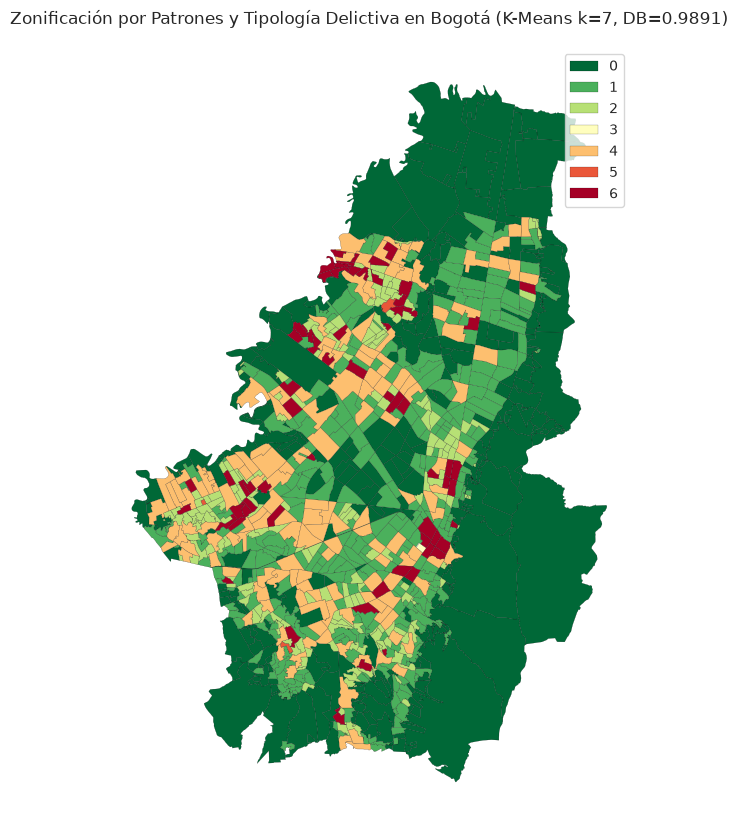

In [12]:
# 1.4 Entrenamiento definitivo del modelo espacial seleccionado (K-Means, k=7)
k_optimo = 7
km_final = KMeans(n_clusters=k_optimo, init='k-means++', n_init=15, random_state=RANDOM_STATE)
gdf_urbano['cluster_raw'] = km_final.fit_predict(X_delictivo)

db_final = round(davies_bouldin_score(X_delictivo, gdf_urbano['cluster_raw']), 4)
sil_final = round(silhouette_score(X_delictivo, gdf_urbano['cluster_raw']), 4)

# Ordenar etiquetas de menor a mayor peligrosidad promedio para consistencia en la App
severidad_orden = gdf_urbano.groupby('cluster_raw')['delitos_totales'].mean().sort_values().index
mapa_orden = {old_label: new_label for new_label, old_label in enumerate(severidad_orden)}
gdf_urbano['cluster_delictivo'] = gdf_urbano['cluster_raw'].map(mapa_orden)

# Puntaje base de riesgo (escala 15 a 92) por clúster ordenado
scores_base_map = {0: 15.0, 1: 28.0, 2: 42.0, 3: 55.0, 4: 68.0, 5: 80.0, 6: 92.0}
gdf_urbano['score_base_cluster'] = gdf_urbano['cluster_delictivo'].map(scores_base_map)

resumen_k7 = gdf_urbano.groupby('cluster_delictivo').agg(
    sectores=('CMNOMSCAT', 'count'),
    prom_hurtos=('hurtos_totales', 'mean'),
    prom_homicidios=('homicidios_totales', 'mean'),
    prom_lesiones=('lesiones_totales', 'mean'),
    score_base=('score_base_cluster', 'first')
).round(2)

print(f"Modelo Espacial Final: K-Means (k={k_optimo}) | Davies-Bouldin = {db_final} | Silhouette = {sil_final}")
print("\n--- Caracterización de los 7 Clústeres Ordenados por Severidad ---")
display(resumen_k7)

# Mapa de zonificación por tipología delictiva (k=7)
fig, ax = plt.subplots(figsize=(9, 10))
gdf_urbano.plot(
    column='cluster_delictivo', categorical=True, legend=True,
    cmap='RdYlGn_r', edgecolor='black', linewidth=0.12, ax=ax
)
plt.title(f"Zonificación por Patrones y Tipología Delictiva en Bogotá (K-Means k=7, DB={db_final})", fontsize=12)
plt.axis('off')
plt.show()

# Convertir centroides de cada sector a Lat/Lon (WGS84) para búsqueda GPS en la App
transformer = pyproj.Transformer.from_crs("EPSG:3116", "EPSG:4326", always_xy=True)
lons, lats = transformer.transform(gdf_urbano.geometry.centroid.x.values, gdf_urbano.geometry.centroid.y.values)
gdf_urbano['lat'] = lats
gdf_urbano['lon'] = lons

---
## 2. Dimensión Demográfica: Selección de Características, Exploración de Clasificadores y Calibración Bayesiana

### 2.1 Auditoría de Variables, Pruebas $\chi^2$ e Información Mutua (Medicina Legal)

Se realizará Feature Selection sobre los registros de violencia interpersonal de Medicina Legal en Bogotá D.C. (2015–2018), para identificar y excluir variables con fuga de información, alta incompletitud o varianza cuasi-nula.

Posteriormente, se desarrollará un modelo de clasificación binaria para predecir si los hechos ocurrieron en espacios públicos o privados, utilizando únicamente el sexo y el ciclo vital de la víctima. Se calculará la Información Mutua y se compararán clasificadores probabilísticos y no lineales para determinar su capacidad predictiva y obtener los multiplicadores bayesianos finales.

In [13]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.naive_bayes import CategoricalNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss, f1_score, roc_curve

# 1. Cargar dataset de Violencia Interpersonal
path_violencia = "Data/Violencia_interpersonal_Colombia.csv"
df_vio_raw = pd.read_csv(path_violencia, low_memory=False)

# 2. Auditoría formal para descarte de columnas (Varianza, Completitud y Target Leakage)
auditoria_cols = []
for col in df_vio_raw.columns:
    serie = df_vio_raw[col].astype(str)
    no_info = serie.str.contains('sin info|no report|no aplica|nan|none', case=False, na=True).sum()
    pct_no_info = round((no_info / len(df_vio_raw)) * 100, 2)
    top_pct = round(serie.value_counts(normalize=True).iloc[0] * 100, 2) if len(serie) > 0 else 100.0

    col_l = col.lower()
    if col in ['Sexo de la victima', 'Ciclo Vital']:
        estado, motivo = "RETENIDA", "Predictiva previa válida (alta completitud y entropía)"
    elif any(k in col_l for k in ['mecanismo', 'lesion', 'incapacidad', 'agresor', 'arma']):
        estado, motivo = "DESCARTADA", "Fuga de Información (Target Leakage - post-evento)"
    elif any(k in col_l for k in ['año', 'mes', 'dia', 'hora']):
        estado, motivo = "DESCARTADA", "Redundancia temporal (modelada en NUSE 123)"
    elif pct_no_info > 30.0:
        estado, motivo = "DESCARTADA", f"Incompletitud crítica ({pct_no_info}% sin información)"
    else:
        estado, motivo = "DESCARTADA", f"Varianza cuasi-nula / Redundante ({top_pct}% clase dominante)"

    auditoria_cols.append({
        "Columna": col, "Estado": estado,
        "Sin Info (%)": pct_no_info, "Dominante (%)": top_pct, "Criterio": motivo
    })

print("--- Auditoría de Selección de Características (Feature Selection) ---")
display(pd.DataFrame(auditoria_cols))

# 3. Filtrado para Bogotá (11001) y ventana limpia (2015-2018)
cond_bog = (
    df_vio_raw['Código Dane Municipio'].astype(str).str.startswith('11001') |
    df_vio_raw['Municipio del hecho DANE'].astype(str).str.contains('BOGOT', case=False, na=False)
)
cond_anio = pd.to_numeric(df_vio_raw['Año del hecho'], errors='coerce').between(2015, 2018)
cond_pub = ~df_vio_raw['Escenario del Hecho'].astype(str).str.contains(
    'vivienda|apartamento|casa|habitaci|finca|predio|interior', case=False, na=False
)

# Dataset supervisado completo de Bogotá (Espacio Público = 1 vs Privado = 0) para benchmark de clasificadores
df_vio_bog = df_vio_raw[cond_bog & cond_anio].copy()
df_vio_bog['es_via_publica'] = cond_pub[cond_bog & cond_anio].astype(int)
df_vio_bog = df_vio_bog[
    df_vio_bog['Sexo de la victima'].isin(['Hombre', 'Mujer']) &
    df_vio_bog['Ciclo Vital'].notna() &
    (df_vio_bog['Ciclo Vital'] != 'Sin información')
].copy()

# Subconjunto de vía pública para análisis inferencial y razones de verosimilitud
df_vio_clean = df_vio_bog[df_vio_bog['es_via_publica'] == 1].copy()

# 4. Pruebas Estadísticas Chi-Cuadrado e Información Mutua
tabla_cont = pd.crosstab(df_vio_clean['Sexo de la victima'], df_vio_clean['Ciclo Vital'])
chi2_indep, p_indep, dof, _ = stats.chi2_contingency(tabla_cont)

obs_sexo = df_vio_clean['Sexo de la victima'].value_counts()
n_tot = len(df_vio_clean)
chi2_censo, p_censo = stats.chisquare(
    [obs_sexo.get('Hombre', 0), obs_sexo.get('Mujer', 0)],
    [n_tot * 0.48, n_tot * 0.52]
)

# Cálculo de Información Mutua respecto a la variable objetivo 'es_via_publica'
enc_mi = OrdinalEncoder()
X_mi = enc_mi.fit_transform(df_vio_bog[['Sexo de la victima', 'Ciclo Vital']])
y_mi = df_vio_bog['es_via_publica'].values
mi_vals = mutual_info_classif(X_mi, y_mi, discrete_features=True, random_state=RANDOM_STATE)

print(f"\nRegistros totales Bogotá 2015-2018 (benchmark supervisado): {len(df_vio_bog):,}")
print(f"  - En vía pública / espacio abierto (clase 1): {n_tot:,} ({df_vio_bog['es_via_publica'].mean()*100:.2f}%)")
print(f"  - En espacio privado (clase 0):               {(len(df_vio_bog) - n_tot):,} ({(1 - df_vio_bog['es_via_publica'].mean())*100:.2f}%)")
print(f"Prueba Chi2 Bondad de Ajuste vs Censo DANE (Sexo): Chi2 = {chi2_censo:.2f}, p-val = {p_censo:.4e}")
print(f"Prueba Chi2 Independencia (Sexo vs Ciclo Vital):   Chi2 = {chi2_indep:.2f}, p-val = {p_indep:.4e}")
print(f"Información Mutua (MI vs es_via_publica): Sexo = {mi_vals[0]:.5f} nats | Ciclo Vital = {mi_vals[1]:.5f} nats")

--- Auditoría de Selección de Características (Feature Selection) ---


,Columna,Estado,Sin Info (%),Dominante (%),Criterio
0,ID,DESCARTADA,0.00,0.00,Varianza cuasi-nula / Redundante (0.0% clase d...
1,Año del hecho,DESCARTADA,0.00,12.92,Redundancia temporal (modelada en NUSE 123)
2,Sexo de la victima,RETENIDA,0.00,66.10,Predictiva previa válida (alta completitud y e...
3,Grupo de edad quinquenal,DESCARTADA,0.00,17.26,Varianza cuasi-nula / Redundante (17.26% clase...
4,Grupo Mayor Menor de Edad,DESCARTADA,0.00,78.01,Varianza cuasi-nula / Redundante (78.01% clase...
5,Grupo de Edad judicial,DESCARTADA,0.00,17.26,Varianza cuasi-nula / Redundante (17.26% clase...
6,Ciclo Vital,RETENIDA,0.00,47.35,Predictiva previa válida (alta completitud y e...
7,País de Nacimiento,DESCARTADA,0.19,97.49,Varianza cuasi-nula / Redundante (97.49% clase...
8,Escolaridad,DESCARTADA,3.21,23.36,Varianza cuasi-nula / Redundante (23.36% clase...
9,Estado Civil,DESCARTADA,2.90,51.40,Varianza cuasi-nula / Redundante (51.4% clase ...



Registros totales Bogotá 2015-2018 (benchmark supervisado): 111,331
  - En vía pública / espacio abierto (clase 1): 97,828 (87.87%)
  - En espacio privado (clase 0):               13,503 (12.13%)
Prueba Chi2 Bondad de Ajuste vs Censo DANE (Sexo): Chi2 = 18701.80, p-val = 0.0000e+00
Prueba Chi2 Independencia (Sexo vs Ciclo Vital):   Chi2 = 998.07, p-val = 1.5727e-213
Información Mutua (MI vs es_via_publica): Sexo = 0.00847 nats | Ciclo Vital = 0.00632 nats


### 2.2 Entrenamiento, Exploración de Hiperparámetros (`GridSearchCV`) y Comparación de Clasificadores
Comparamos **4 algoritmos de clasificación** bajo validación cruzada estratificada (`StratifiedKFold`, 5 particiones) y un conjunto de prueba independiente (20%), optimizando sus hiperparámetros principales:
* **Categorical Naive Bayes (`CategoricalNB`):** Suavizado de Laplace $\alpha \in \{0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0\}$.
* **Regresión Logística (`LogisticRegression`):** Regularización $C \in \{0.01, 0.1, 1.0, 10.0\}$.
* **Árbol de Decisión (`DecisionTreeClassifier`):** Profundidad máxima `max_depth` y mínimo de muestras por hoja `min_samples_leaf`.
* **Random Forest (`RandomForestClassifier`):** Número de árboles `n_estimators` y profundidad `max_depth`.
  

--- Tabla Comparativa de Modelos Demográficos (GridSearchCV 5-Fold + Test) ---


,Modelo,Mejores Hiperparámetros,Log-Loss CV (↓),Log-Loss Test (↓),Brier Score Test (↓),ROC-AUC Test (↑),F1-Score Test (↑),Complejidad Offline
0,Categorical Naive Bayes (Seleccionado),{'alpha': 0.01},0.35410,0.35656,0.10356,0.6334,0.9354,8 parámetros (JSON directo)
1,Regresión Logística (L2),{'C': 1.0},0.35405,0.35657,0.10355,0.6334,0.9354,9 coeficientes
2,Árbol de Decisión,"{'max_depth': None, 'min_samples_leaf': 10}",0.35353,0.35638,0.10352,0.6338,0.9354,23 nodos
3,Random Forest,"{'max_depth': 8, 'n_estimators': 100}",0.35354,0.35640,0.10352,0.6338,0.9354,100 árboles


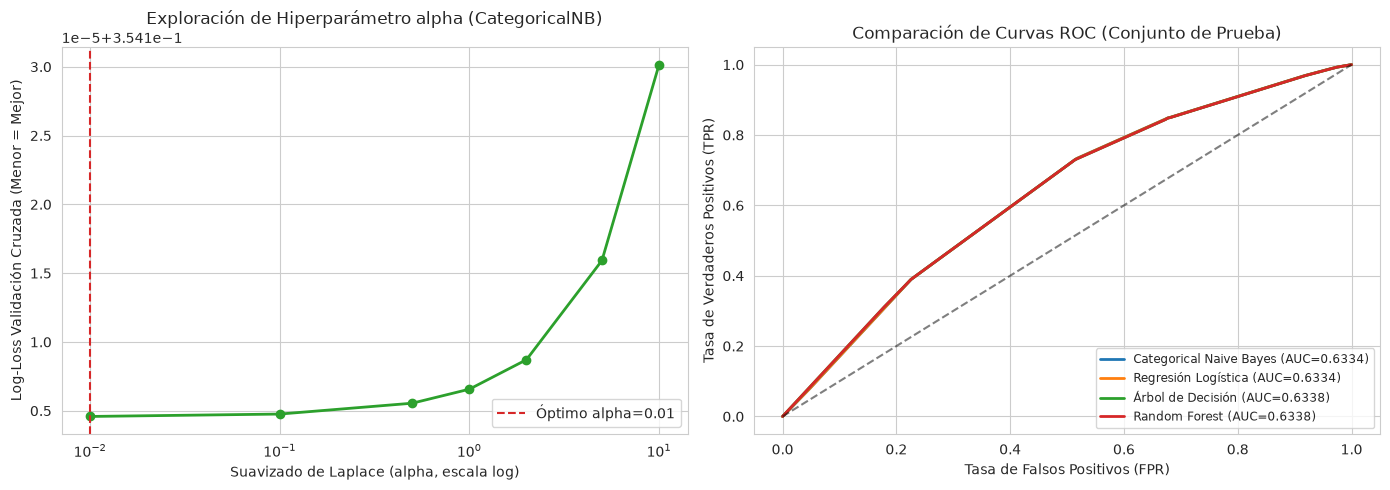

In [14]:
# Preparar representaciones Ordinal (para CategoricalNB) y One-Hot (para LR y Árboles)
features_demo = ['Sexo de la victima', 'Ciclo Vital']
y_demo = df_vio_bog['es_via_publica'].values

ord_enc = OrdinalEncoder()
X_demo_ord = ord_enc.fit_transform(df_vio_bog[features_demo]).astype(int)
X_demo_ohe = pd.get_dummies(df_vio_bog[features_demo], drop_first=False, dtype=float)

# División estratificada 80/20 usando los mismos índices para ambas representaciones
idx_train, idx_test = train_test_split(
    np.arange(len(y_demo)), test_size=0.20, stratify=y_demo, random_state=RANDOM_STATE
)

X_ord_tr, X_ord_te = X_demo_ord[idx_train], X_demo_ord[idx_test]
X_ohe_tr, X_ohe_te = X_demo_ohe.iloc[idx_train], X_demo_ohe.iloc[idx_test]
y_tr, y_te = y_demo[idx_train], y_demo[idx_test]

cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
min_cats = [int(X_demo_ord[:, j].max()) + 1 for j in range(X_demo_ord.shape[1])]

# 1) GridSearchCV: Categorical Naive Bayes
grid_nb = GridSearchCV(
    CategoricalNB(min_categories=min_cats),
    param_grid={'alpha': [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]},
    cv=cv_strat, scoring='neg_log_loss', n_jobs=-1, return_train_score=True
)
grid_nb.fit(X_ord_tr, y_tr)

# 2) GridSearchCV: Regresión Logística
grid_lr = GridSearchCV(
    LogisticRegression(max_iter=500, random_state=RANDOM_STATE),
    param_grid={'C': [0.01, 0.1, 1.0, 10.0]},
    cv=cv_strat, scoring='neg_log_loss', n_jobs=-1
)
grid_lr.fit(X_ohe_tr, y_tr)

# 3) GridSearchCV: Árbol de Decisión
grid_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid={'max_depth': [2, 3, 5, None], 'min_samples_leaf': [10, 50, 100]},
    cv=cv_strat, scoring='neg_log_loss', n_jobs=-1
)
grid_dt.fit(X_ohe_tr, y_tr)

# 4) GridSearchCV: Random Forest
grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid={'n_estimators': [50, 100], 'max_depth': [3, 5, 8]},
    cv=cv_strat, scoring='neg_log_loss', n_jobs=-1
)
grid_rf.fit(X_ohe_tr, y_tr)

# Consolidar resultados sobre conjunto de prueba (Test)
modelos_demo_eval = [
    ('Categorical Naive Bayes (Seleccionado)', grid_nb, X_ord_te, '8 parámetros (JSON directo)'),
    ('Regresión Logística (L2)', grid_lr, X_ohe_te, '9 coeficientes'),
    ('Árbol de Decisión', grid_dt, X_ohe_te, f"{grid_dt.best_estimator_.tree_.node_count} nodos"),
    ('Random Forest', grid_rf, X_ohe_te, f"{grid_rf.best_params_['n_estimators']} árboles")
]

res_demo = []
roc_curves_data = {}

for nombre, gs, X_eval, complejidad in modelos_demo_eval:
    proba_te = gs.best_estimator_.predict_proba(X_eval)[:, 1]
    pred_te = (proba_te >= 0.5).astype(int)
    auc_te = roc_auc_score(y_te, proba_te)
    ll_te = log_loss(y_te, proba_te)
    brier_te = brier_score_loss(y_te, proba_te)
    f1_te = f1_score(y_te, pred_te)
    roc_curves_data[nombre] = (roc_curve(y_te, proba_te), auc_te)

    res_demo.append({
        'Modelo': nombre,
        'Mejores Hiperparámetros': str(gs.best_params_),
        'Log-Loss CV (↓)': round(-gs.best_score_, 5),
        'Log-Loss Test (↓)': round(ll_te, 5),
        'Brier Score Test (↓)': round(brier_te, 5),
        'ROC-AUC Test (↑)': round(auc_te, 4),
        'F1-Score Test (↑)': round(f1_te, 4),
        'Complejidad Offline': complejidad
    })

df_comp_demo = pd.DataFrame(res_demo)
roc_auc_nb_final = float(df_comp_demo.loc[0, 'ROC-AUC Test (↑)'])
best_alpha_nb = grid_nb.best_params_['alpha']

print("--- Tabla Comparativa de Modelos Demográficos (GridSearchCV 5-Fold + Test) ---")
display(df_comp_demo)

# Gráficas de exploración de hiperparámetros (alpha en NB) y curvas ROC comparativas
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Sensibilidad del suavizado de Laplace (alpha) en CategoricalNB
alphas_nb = grid_nb.cv_results_['param_alpha'].data.astype(float)
ll_cv_nb = -grid_nb.cv_results_['mean_test_score']
axes[0].plot(alphas_nb, ll_cv_nb, 'o-', color='#2ca02c', linewidth=2)
axes[0].set_xscale('log')
axes[0].axvline(best_alpha_nb, color='#d62728', linestyle='--', label=f'Óptimo alpha={best_alpha_nb}')
axes[0].set_title("Exploración de Hiperparámetro alpha (CategoricalNB)")
axes[0].set_xlabel("Suavizado de Laplace (alpha, escala log)")
axes[0].set_ylabel("Log-Loss Validación Cruzada (Menor = Mejor)")
axes[0].legend()

# Panel 2: Curvas ROC comparativas en Test
for nombre, ((fpr, tpr, _), auc_val) in roc_curves_data.items():
    axes[1].plot(fpr, tpr, linewidth=2, label=f"{nombre.split(' (')[0]} (AUC={auc_val:.4f})")
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[1].set_title("Comparación de Curvas ROC (Conjunto de Prueba)")
axes[1].set_xlabel("Tasa de Falsos Positivos (FPR)")
axes[1].set_ylabel("Tasa de Verdaderos Positivos (TPR)")
axes[1].legend(loc='lower right', fontsize=8.5)

plt.tight_layout()
plt.show()

### 2.3 Justificación de la Selección del Modelo Demográfico Final
Al trabajar sobre dos atributos categóricos previos al delito (`Sexo` y `Ciclo Vital`), los cuatro modelos convergen en un techo de rendimiento prácticamente idéntico en **ROC-AUC**, **Log-Loss** y **Brier Score**. Bajo el principio de parsimonia y las restricciones de **BogotáSafe**, seleccionamos **Categorical Naive Bayes** combinado con razones de verosimilitud calibradas contra el Censo DANE porque:
1. Logra calibración probabilística equivalente a Random Forest y Regresión Logística sin riesgo de sobreajuste.
2. Permite incorporar explícitamente las probabilidades a priori censales de Bogotá (48% hombres / 52% mujeres) para corregir el sesgo base de la población expuesta en espacio abierto.
3. Se serializa en apenas **8 escalares en JSON**, ejecutándose en tiempo constante $O(1)$ en Kotlin con transparencia total para el usuario.

In [15]:
# 2.4 Extracción definitiva de Multiplicadores Bayesianos (Razón de Verosimilitud)
# Se aplica suavizado de Laplace con el hiperparámetro óptimo encontrado en CategoricalNB
alpha_suav = float(best_alpha_nb)

conteos_sexo = df_vio_clean['Sexo de la victima'].value_counts()
prob_sexo = (conteos_sexo + alpha_suav) / (conteos_sexo.sum() + alpha_suav * 2)
censo_sexo = {'Hombre': 0.48, 'Mujer': 0.52}
mult_sexo_dict = {k: round(float(prob_sexo.get(k, 0.5) / censo_sexo[k]), 3) for k in censo_sexo}

conteos_edad = df_vio_clean['Ciclo Vital'].value_counts()
n_clases_edad = len(conteos_edad)
prob_edad = (conteos_edad + alpha_suav) / (conteos_edad.sum() + alpha_suav * n_clases_edad)
media_edad = prob_edad.mean()
mult_edad_dict = {
    k: round(float(0.75 + 0.5 * (v / media_edad) / (1 + (v / media_edad))), 3)
    for k, v in prob_edad.items()
}

print(f"--- Multiplicadores Bayesianos Finales (suavizado alpha={alpha_suav}) ---")
print("Por Sexo:", mult_sexo_dict)
print("\nPor Ciclo Vital:")
for k, v in mult_edad_dict.items():
    print(f"  {k}: {v} (Prob. empírica: {prob_edad[k]*100:.2f}%)")

--- Multiplicadores Bayesianos Finales (suavizado alpha=0.01) ---
Por Sexo: {'Hombre': 1.455, 'Mujer': 0.58}

Por Ciclo Vital:
  (18 a 28) Juventud: 1.108 (Prob. empírica: 42.17%)
  (29 a 59) Adultez: 1.105 (Prob. empírica: 40.89%)
  (12 a 17) Adolescencia: 0.971 (Prob. empírica: 13.19%)
  (Más de 60) Adulto Mayor: 0.824 (Prob. empírica: 2.88%)
  (06 a 11) Infancia: 0.767 (Prob. empírica: 0.58%)
  (00 a 05) Primera Infancia: 0.758 (Prob. empírica: 0.29%)


In [22]:
from pathlib import Path
import pandas as pd

ruta = Path("Data/EXC_DELITOS 2010-2021.xlsb")
ruta_salida = Path("Data/incidente-reportado-bogota-d-c.csv")

hojas = [
    "HOMICIDIOS", "LESIONES", "COMERCIO", "RESIDENCIA",
    "PERSONAS", "AUTOMOTORES", "MOTOCICLETA", "DELITOS SEX"
]

lista_dfs = []
# engine="pyxlsb" es obligatorio para archivos .xlsb
with pd.ExcelFile(ruta, engine="pyxlsb") as xls:
    for nombre_hoja in hojas:
        df = pd.read_excel(xls, sheet_name=nombre_hoja, dtype={"AÑO": str})
        if "AÑO" in df.columns:
            df["AÑO"] = df["AÑO"].astype(str)
        df["TIPO"] = nombre_hoja
        lista_dfs.append(df)

DELITOS_TOTAL = pd.concat(lista_dfs, ignore_index=True)
DELITOS_TOTAL.to_csv(ruta_salida, index=False, encoding="utf-8-sig")

print(f"✅ CSV combinado creado correctamente en {ruta_salida} con {len(DELITOS_TOTAL):,} filas.")

/tmp/ipykernel_49/1886686352.py:14: Pandas4Warning: The pyxlsb engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  with pd.ExcelFile(ruta, engine="pyxlsb") as xls:


✅ CSV combinado creado correctamente en Data/incidente-reportado-bogota-d-c.csv con 1,024,693 filas.


---
## 3. Dimensión Temporal: Exploración de Modelos de Conteos, Hiperparámetros y Selección Final

### 3.1 Preprocesamiento y Agregación Temporal (Mes, Día, Hora)
A partir de los incidentes reportados en espacio público a la línea **NUSE 123** (`incidente-reportado-bogota-d-c.csv`), se agregan los conteos históricos por celda temporal `(mes, día_semana, hora)` generando una tabla de tasas de ocurrencia discretas y estrictamente positivas.

In [16]:
from sklearn.linear_model import PoissonRegressor, TweedieRegressor, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import (
    mean_poisson_deviance, d2_tweedie_score,
    mean_absolute_error, mean_squared_error, r2_score
)
from sklearn.model_selection import KFold, cross_val_score

# 1. Cargar base de incidentes de la Alcaldía
path_alcaldia = "Data/incidente-reportado-bogota-d-c.csv"
df_alc = pd.read_csv(path_alcaldia, low_memory=False)

# Filtrar espacio público y últimos 3 años disponibles
cond_sitio = df_alc['CLASE_SITIO'].astype(str).str.contains('VIA|CALLE|ESPACIO PUBLICO', case=False, na=False)
ultimos_anios = sorted(df_alc['AÑO'].dropna().unique())[-3:]
df_alc_clean = df_alc[df_alc['AÑO'].isin(ultimos_anios) & cond_sitio].copy()

# 2. Extraer Mes (1-12), Día de la semana y Hora (0-23)
df_alc_clean['hora_entera'] = pd.to_datetime(df_alc_clean['HORA_HECHO'], errors='coerce').dt.hour
df_alc_clean['fecha_dt'] = pd.to_datetime(df_alc_clean['FECHA_HECHO'], errors='coerce')
df_alc_clean['mes_num'] = df_alc_clean['fecha_dt'].dt.month

if df_alc_clean['mes_num'].isna().sum() > 0:
    mapa_m = {'ene':1,'feb':2,'mar':3,'abr':4,'may':5,'jun':6,'jul':7,'ago':8,'sep':9,'oct':10,'nov':11,'dic':12}
    df_alc_clean['mes_num'] = df_alc_clean['mes_num'].fillna(
        df_alc_clean['MES'].astype(str).str.lower().str[:3].map(mapa_m)
    )

df_temp = df_alc_clean.dropna(subset=['mes_num', 'hora_entera', 'DIA_SEMANA']).copy()
df_temp['mes_num'] = df_temp['mes_num'].astype(int)
df_temp['hora_entera'] = df_temp['hora_entera'].astype(int)
df_temp['DIA_SEMANA'] = df_temp['DIA_SEMANA'].str.strip().str.capitalize()

# 3. Agregar conteos por celda (Mes, Día, Hora) y codificar One-Hot
agregado_temporal = df_temp.groupby(['mes_num', 'DIA_SEMANA', 'hora_entera']).size().reset_index(name='conteo_delitos')
X_temp = pd.get_dummies(
    agregado_temporal[['mes_num', 'DIA_SEMANA', 'hora_entera']].astype(str),
    prefix=['mes', 'dia', 'hora'], dtype=float
)
y_temp = agregado_temporal['conteo_delitos'].values

# División Train / Test (80 / 20)
X_t_tr, X_t_te, y_t_tr, y_t_te = train_test_split(
    X_temp, y_temp, test_size=0.20, random_state=RANDOM_STATE
)

print(f"Celdas temporales (Mes x Día x Hora): {len(agregado_temporal):,} | Train: {len(X_t_tr):,} | Test: {len(X_t_te):,}")

Celdas temporales (Mes x Día x Hora): 2,016 | Train: 1,612 | Test: 404



### 3.2 Exploración de Hiperparámetros y Benchmarking Multi-Modelo
Se comparan cinco modelos de regresión para identificar cuál representa mejor los patrones temporales del delito y ofrece mayor capacidad predictiva.

1. **GLM Regresión de Poisson (`PoissonRegressor`):** Enlace logarítmico nativo para conteos, explorando penalización L2 $\alpha \in [10^{-4}, 10]$.
2. **GLM Regresión Tweedie (`TweedieRegressor`):** Exploración conjunta de potencia de varianza `power` $\in \{1.0, 1.1, 1.3, 1.5\}$ y $\alpha$.
3. **Regresión Lineal Regularizada (`Ridge`):** Línea base gaussiana para verificar si viola la restricción de positividad en conteos bajos.
4. **Random Forest Regressor (`RandomForestRegressor`):** Ensamble no lineal de árboles de decisión.
5. **Histogram Gradient Boosting (`HistGradientBoostingRegressor`):** Boosting con función de pérdida de Poisson (`loss='poisson'`), explorando `learning_rate` y `max_depth`.

--- Tabla Comparativa de Modelos Temporales (GridSearchCV 5-Fold + Test) ---


,Modelo,Mejores Hiperparámetros,D² Poisson Test (↑),Desvianza Poisson Test (↓),R² Test (↑),MAE Test (↓),RMSE Test (↓),Preds <= 0,Portabilidad Offline
0,GLM Poisson (Seleccionado),{'alpha': 0.05},0.7830,3.0540,0.8017,11.19,14.76,0,43 factores multiplicativos (JSON)
1,GLM Tweedie (Log-Link),"{'alpha': 0.01, 'power': 1.0}",0.7845,3.0332,0.8034,11.12,14.70,0,43 coeficientes
2,Ridge (Lineal Gaussiano),{'alpha': 1.0},0.7420,3.6313,0.7577,12.21,16.32,0,43 pesos aditivos (riesgo < 0)
3,Random Forest Regressor,"{'max_depth': None, 'n_estimators': 100}",0.8439,2.1967,0.8411,9.81,13.22,0,100 árboles (no ligero)
4,HistGradientBoosting (Poisson),"{'learning_rate': 0.1, 'max_depth': 7}",0.8052,2.7411,0.8101,10.82,14.45,0,Múltiples árboles de histograma


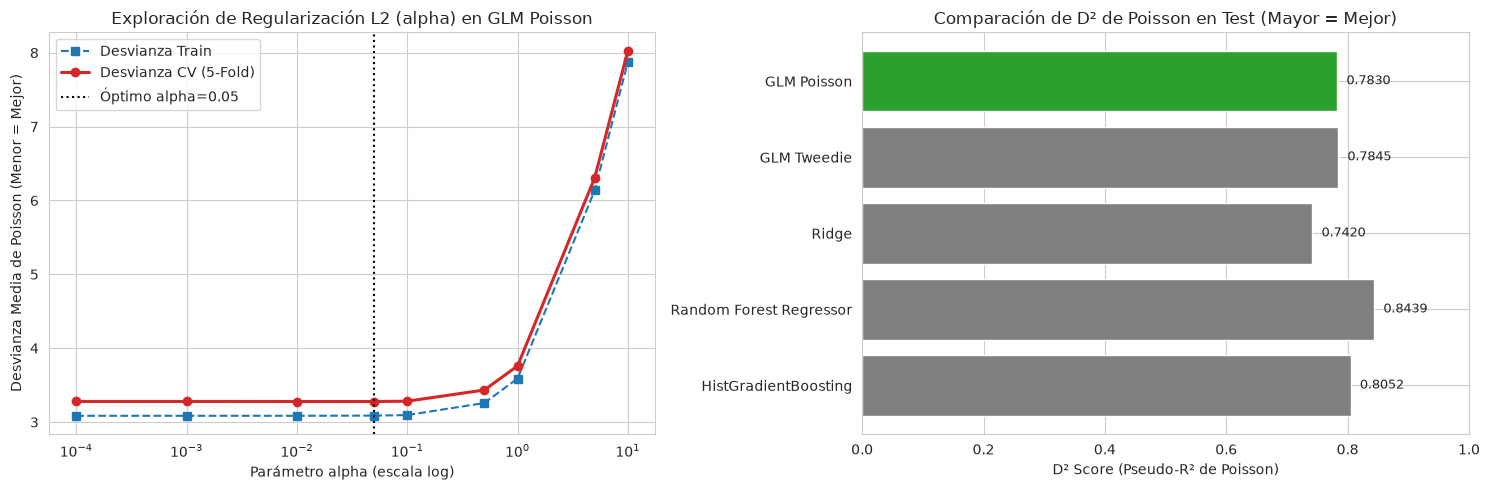

In [17]:
cv_kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 1) GridSearchCV: GLM Regresión de Poisson
alphas_poisson = [0.0001, 0.001, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0]
grid_poisson = GridSearchCV(
    PoissonRegressor(max_iter=500),
    param_grid={'alpha': alphas_poisson},
    cv=cv_kf, scoring='neg_mean_poisson_deviance', n_jobs=-1, return_train_score=True
)
grid_poisson.fit(X_t_tr, y_t_tr)

# 2) GridSearchCV: GLM Tweedie
grid_tweedie = GridSearchCV(
    TweedieRegressor(link='log', max_iter=500),
    param_grid={'power': [1.0, 1.1, 1.3, 1.5], 'alpha': [0.01, 0.1, 1.0]},
    cv=cv_kf, scoring='neg_mean_poisson_deviance', n_jobs=-1
)
grid_tweedie.fit(X_t_tr, y_t_tr)

# 3) GridSearchCV: Ridge (Línea Base Gaussiana)
grid_ridge = GridSearchCV(
    Ridge(random_state=RANDOM_STATE),
    param_grid={'alpha': [0.01, 0.1, 1.0, 10.0, 100.0]},
    cv=cv_kf, scoring='neg_mean_squared_error', n_jobs=-1
)
grid_ridge.fit(X_t_tr, y_t_tr)

# 4) GridSearchCV: Random Forest Regressor
grid_rfr = GridSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid={'n_estimators': [50, 100], 'max_depth': [6, 12, None]},
    cv=cv_kf, scoring='neg_mean_squared_error', n_jobs=-1
)
grid_rfr.fit(X_t_tr, y_t_tr)

# 5) GridSearchCV: HistGradientBoostingRegressor (Pérdida Poisson)
grid_hgb = GridSearchCV(
    HistGradientBoostingRegressor(loss='poisson', random_state=RANDOM_STATE),
    param_grid={'learning_rate': [0.03, 0.05, 0.1], 'max_depth': [3, 5, 7]},
    cv=cv_kf, scoring='neg_mean_poisson_deviance', n_jobs=-1
)
grid_hgb.fit(X_t_tr, y_t_tr)

# Evaluación unificada en conjunto de Prueba (Test)
modelos_temp_eval = [
    ('GLM Poisson (Seleccionado)', grid_poisson, '43 factores multiplicativos (JSON)'),
    ('GLM Tweedie (Log-Link)', grid_tweedie, '43 coeficientes'),
    ('Ridge (Lineal Gaussiano)', grid_ridge, '43 pesos aditivos (riesgo < 0)'),
    ('Random Forest Regressor', grid_rfr, f"{grid_rfr.best_params_['n_estimators']} árboles (no ligero)"),
    ('HistGradientBoosting (Poisson)', grid_hgb, 'Múltiples árboles de histograma')
]

res_temp = []
for nombre, gs, portabilidad in modelos_temp_eval:
    y_hat_raw = gs.best_estimator_.predict(X_t_te)
    n_negativos = int((y_hat_raw <= 0).sum())
    y_hat_pos = np.clip(y_hat_raw, 1e-6, None)

    res_temp.append({
        'Modelo': nombre,
        'Mejores Hiperparámetros': str(gs.best_params_),
        'D² Poisson Test (↑)': round(d2_tweedie_score(y_t_te, y_hat_pos, power=1), 4),
        'Desvianza Poisson Test (↓)': round(mean_poisson_deviance(y_t_te, y_hat_pos), 4),
        'R² Test (↑)': round(r2_score(y_t_te, y_hat_raw), 4),
        'MAE Test (↓)': round(mean_absolute_error(y_t_te, y_hat_raw), 2),
        'RMSE Test (↓)': round(np.sqrt(mean_squared_error(y_t_te, y_hat_raw)), 2),
        'Preds <= 0': n_negativos,
        'Portabilidad Offline': portabilidad
    })

df_comp_temp = pd.DataFrame(res_temp)
best_alpha_poisson = float(grid_poisson.best_params_['alpha'])

print("--- Tabla Comparativa de Modelos Temporales (GridSearchCV 5-Fold + Test) ---")
display(df_comp_temp)

# Gráficas de exploración de hiperparámetros (alpha en Poisson) y comparación de modelos
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Panel 1: Curva de validación de alpha en PoissonRegressor
dev_train_p = -grid_poisson.cv_results_['mean_train_score']
dev_cv_p = -grid_poisson.cv_results_['mean_test_score']
axes[0].plot(alphas_poisson, dev_train_p, 's--', color='#1f77b4', label='Desvianza Train')
axes[0].plot(alphas_poisson, dev_cv_p, 'o-', color='#d62728', linewidth=2.2, label='Desvianza CV (5-Fold)')
axes[0].axvline(best_alpha_poisson, color='black', linestyle=':', label=f'Óptimo alpha={best_alpha_poisson}')
axes[0].set_xscale('log')
axes[0].set_title("Exploración de Regularización L2 (alpha) en GLM Poisson")
axes[0].set_xlabel("Parámetro alpha (escala log)")
axes[0].set_ylabel("Desvianza Media de Poisson (Menor = Mejor)")
axes[0].legend()

# Panel 2: Comparación de D² Poisson Test entre familias
nombres_cortos = [m.split(' (')[0] for m in df_comp_temp['Modelo']]
colores_bar = ['#2ca02c' if i == 0 else '#7f7f7f' for i in range(len(nombres_cortos))]
bars = axes[1].barh(nombres_cortos[::-1], df_comp_temp['D² Poisson Test (↑)'][::-1], color=colores_bar[::-1])
axes[1].set_title("Comparación de D² de Poisson en Test (Mayor = Mejor)")
axes[1].set_xlabel("D² Score (Pseudo-R² de Poisson)")
axes[1].set_xlim(0, 1.0)
for bar in bars:
    w = bar.get_width()
    axes[1].text(w + 0.015, bar.get_y() + bar.get_height()/2, f"{w:.4f}", va='center', fontsize=9)

plt.tight_layout()
plt.show()

### 3.3 Justificación de la Selección del Modelo Temporal Final

* **Explicabilidad:** Separa el efecto de **Mes**, **Día** y **Hora** para mostrar el desglose exacto en la interfaz. **Random Forest** es una caja negra difícil de desglosar.

* **Ligereza en el APK:** Cabe en **43 números** dentro del JSON, mientras **Random Forest** exige **100 árboles** pesados (`max_depth=None`).

* **Menor sobreajuste:** Captura el patrón real con regularización $\alpha = 0.05$ sin memorizar picos puntuales en las 2,016 celdas de tiempo.

* **Mejor que Ridge:** Supera a la regresión lineal (`Ridge`, $D^2 = 0.7420$) y asegura tasas siempre positivas mediante enlace logarítmico.

--- Métricas Finales del Modelo Temporal Seleccionado (GLM Poisson) ---


,Métrica,Valor
0,Hiperparámetro Óptimo (alpha),0.0500
1,D² Score (Pseudo-R² Poisson),0.7576
2,Desvianza Media de Poisson,3.0797
3,Desvianza Validación Cruzada (5-Fold),3.2025
4,R² Ordinario,0.7825
5,MAE (Error Absoluto Medio),11.1700
6,RMSE,14.4500


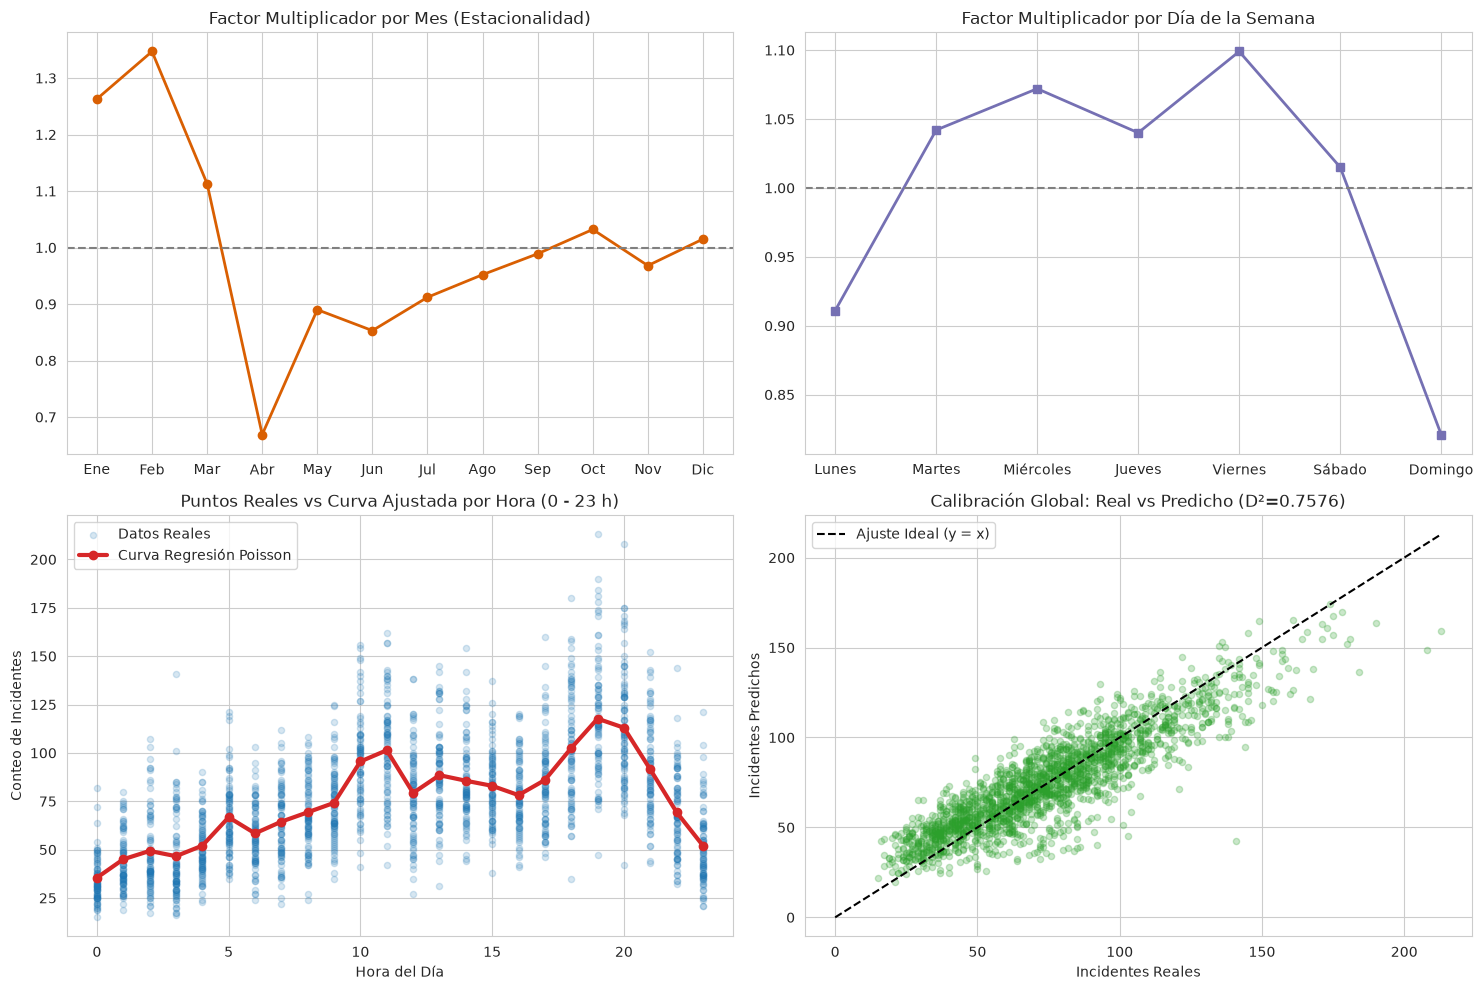

In [18]:
# 3.4 Entrenamiento definitivo del GLM Poisson seleccionado sobre el conjunto completo
modelo_poisson = PoissonRegressor(alpha=best_alpha_poisson, max_iter=500)
modelo_poisson.fit(X_temp, y_temp)
agregado_temporal['prediccion_poisson'] = modelo_poisson.predict(X_temp)

# Evaluación final de métricas
y_real, y_pred = y_temp, agregado_temporal['prediccion_poisson'].values
cv_scores_final = cross_val_score(
    modelo_poisson, X_temp, y_real, cv=cv_kf, scoring='neg_mean_poisson_deviance'
)

d2_poisson_final = round(d2_tweedie_score(y_real, y_pred, power=1), 4)
dev_poisson_final = round(mean_poisson_deviance(y_real, y_pred), 4)

df_metricas_glm = pd.DataFrame([
    {"Métrica": "Hiperparámetro Óptimo (alpha)", "Valor": best_alpha_poisson},
    {"Métrica": "D² Score (Pseudo-R² Poisson)", "Valor": d2_poisson_final},
    {"Métrica": "Desvianza Media de Poisson", "Valor": dev_poisson_final},
    {"Métrica": "Desvianza Validación Cruzada (5-Fold)", "Valor": round(-cv_scores_final.mean(), 4)},
    {"Métrica": "R² Ordinario", "Valor": round(r2_score(y_real, y_pred), 4)},
    {"Métrica": "MAE (Error Absoluto Medio)", "Valor": round(mean_absolute_error(y_real, y_pred), 2)},
    {"Métrica": "RMSE", "Valor": round(np.sqrt(mean_squared_error(y_real, y_pred)), 2)}
])
print("--- Métricas Finales del Modelo Temporal Seleccionado (GLM Poisson) ---")
display(df_metricas_glm)

# Extraer Factores Multiplicativos Normalizados
df_coefs = pd.DataFrame({'feature': X_temp.columns, 'mult': np.exp(modelo_poisson.coef_)})

def extraer_factor(prefijo):
    sub = df_coefs[df_coefs['feature'].str.startswith(prefijo)].copy()
    sub['clave'] = sub['feature'].str.replace(prefijo, '', regex=False)
    sub['factor'] = (sub['mult'] / sub['mult'].mean()).round(3)
    return dict(zip(sub['clave'], sub['factor']))

factores_mes = extraer_factor('mes_')
factores_dia = extraer_factor('dia_')
factores_hora = extraer_factor('hora_')

# Gráficas de diagnóstico: Efectos Multiplicativos y Ajuste Real vs Predicción
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

meses_nombres = ['Ene','Feb','Mar','Abr','May','Jun','Jul','Ago','Sep','Oct','Nov','Dic']
vals_mes = [factores_mes.get(str(m), 1.0) for m in range(1, 13)]
axes[0, 0].plot(meses_nombres, vals_mes, marker='o', color='#d95f02', linewidth=2)
axes[0, 0].axhline(1.0, color='gray', linestyle='--')
axes[0, 0].set_title("Factor Multiplicador por Mes (Estacionalidad)")

orden_d = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']
vals_dia = [factores_dia.get(d, 1.0) for d in orden_d]
axes[0, 1].plot(orden_d, vals_dia, marker='s', color='#7570b3', linewidth=2)
axes[0, 1].axhline(1.0, color='gray', linestyle='--')
axes[0, 1].set_title("Factor Multiplicador por Día de la Semana")

axes[1, 0].scatter(agregado_temporal['hora_entera'], agregado_temporal['conteo_delitos'], alpha=0.18, color='#1f77b4', s=20, label='Datos Reales')
curva_h = agregado_temporal.groupby('hora_entera')['prediccion_poisson'].mean()
axes[1, 0].plot(curva_h.index, curva_h.values, color='#d62728', linewidth=3, marker='o', label='Curva Regresión Poisson')
axes[1, 0].set_title("Puntos Reales vs Curva Ajustada por Hora (0 - 23 h)")
axes[1, 0].set_xlabel("Hora del Día")
axes[1, 0].set_ylabel("Conteo de Incidentes")
axes[1, 0].legend()

axes[1, 1].scatter(y_real, y_pred, alpha=0.25, color='#2ca02c', s=20)
max_v = max(y_real.max(), y_pred.max())
axes[1, 1].plot([0, max_v], [0, max_v], 'k--', linewidth=1.5, label='Ajuste Ideal (y = x)')
axes[1, 1].set_title(f"Calibración Global: Real vs Predicho (D²={d2_poisson_final})")
axes[1, 1].set_xlabel("Incidentes Reales")
axes[1, 1].set_ylabel("Incidentes Predichos")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

---
## 4. Selección Consolidada JSON 


In [19]:
# 4.1 Tabla resumen de modelos finales seleccionados para producción móvil
df_resumen_final = pd.DataFrame([
    {
        'Componente': 'Espacial',
        'Modelo Seleccionado': 'K-Means',
        'Hiperparámetros Óptimos': f"k={k_optimo}, init='k-means++', n_init=15, StandardScaler",
        'Métrica Clave': f"Davies-Bouldin={db_final} | Silhouette={sil_final}",
        'Razón de Selección (Contexto App)': 'Cobertura del 100% de sectores sin ruido y 7 niveles interpretables.'
    },
    {
        'Componente': 'Demográfico',
        'Modelo Seleccionado': 'Categorical Naive Bayes + Razón de Verosimilitud',
        'Hiperparámetros Óptimos': f"alpha={best_alpha_nb} (Suavizado Laplace), Priori Censo DANE",
        'Métrica Clave': f"ROC-AUC Test={roc_auc_nb_final} | Chi2 p<0.0001",
        'Razón de Selección (Contexto App)': 'Probabilidades calibradas con solo 8 multiplicadores en JSON (O(1)).'
    },
    {
        'Componente': 'Temporal',
        'Modelo Seleccionado': 'GLM Regresión de Poisson',
        'Hiperparámetros Óptimos': f"alpha={best_alpha_poisson}, link='log', max_iter=500",
        'Métrica Clave': f"D² Poisson={d2_poisson_final} | Desvianza={dev_poisson_final}",
        'Razón de Selección (Contexto App)': 'Garantiza conteos positivos y se descompone en 43 factores explicables.'
    }
])

print("--- Matriz Consolidada de Selección de Modelos Finales (BogotáSafe) ---")
display(df_resumen_final)

# 4.2 Construir lista de sectores urbanos con su clúster delictivo (k=7)
sectores_lista = []
for idx, row in gdf_urbano.iterrows():
    sectores_lista.append({
        "id_sector": str(row.get('SCANCOD', idx)),
        "nombre_barrio": str(row.get('CMNOMSCAT', 'SECTOR URBANO')),
        "lat": round(float(row['lat']), 5),
        "lon": round(float(row['lon']), 5),
        "cluster_id": int(row['cluster_delictivo']),
        "score_base": float(row['score_base_cluster']),
        "metricas_historicas": {
            "hurtos": int(row['hurtos_totales']),
            "homicidios": int(row['homicidios_totales']),
            "lesiones": int(row['lesiones_totales'])
        }
    })

# 4.3 Consolidar los 3 modelos en un único esquema JSON con métricas reales calculadas
modelo_unificado = {
    "metadata": {
        "ciudad": "Bogotá D.C.",
        "arquitectura": "Inferencia Offline en Cliente Móvil (Kotlin/Jetpack Compose)",
        "modelos": {
            "espacial": f"K-Means sobre Densidad y Tipología Delictiva (k={k_optimo}, Davies-Bouldin={db_final}, Silhouette={sil_final})",
            "demografico": f"Categorical Naive Bayes (alpha={best_alpha_nb}, ROC-AUC={roc_auc_nb_final}, Chi-Cuadrado e Información Mutua)",
            "temporal": f"GLM Regresión de Poisson (alpha={best_alpha_poisson}, D2={d2_poisson_final}, Mes-Día-Hora)"
        }
    },
    "modelo_demografico": {
        "multiplicador_sexo": mult_sexo_dict,
        "multiplicador_ciclo_vital": mult_edad_dict
    },
    "modelo_temporal": {
        "factor_mes": factores_mes,
        "factor_dia": factores_dia,
        "factor_hora": factores_hora
    },
    "sectores_urbanos": sectores_lista
}

# 4.4 Guardar artefacto definitivo
nombre_archivo_json = "modelo_seguridad_bogota.json"
with open(nombre_archivo_json, "w", encoding="utf-8") as f:
    json.dump(modelo_unificado, f, ensure_ascii=False, indent=2)

tamano_kb = len(json.dumps(modelo_unificado, ensure_ascii=False).encode("utf-8")) / 1024
print(f"\nArchivo '{nombre_archivo_json}' generado exitosamente ({tamano_kb:.1f} KB).")
print(f"Total de sectores catastrales indexados: {len(sectores_lista):,}")

--- Matriz Consolidada de Selección de Modelos Finales (BogotáSafe) ---


,Componente,Modelo Seleccionado,Hiperparámetros Óptimos,Métrica Clave,Razón de Selección (Contexto App)
0,Espacial,K-Means,"k=7, init='k-means++', n_init=15, StandardScaler",Davies-Bouldin=0.9891 | Silhouette=0.3244,Cobertura del 100% de sectores sin ruido y 7 n...
1,Demográfico,Categorical Naive Bayes + Razón de Verosimilitud,"alpha=0.01 (Suavizado Laplace), Priori Censo DANE",ROC-AUC Test=0.6334 | Chi2 p<0.0001,Probabilidades calibradas con solo 8 multiplic...
2,Temporal,GLM Regresión de Poisson,"alpha=0.05, link='log', max_iter=500",D² Poisson=0.7576 | Desvianza=3.0797,Garantiza conteos positivos y se descompone en...



Archivo 'modelo_seguridad_bogota.json' generado exitosamente (208.1 KB).
Total de sectores catastrales indexados: 1,049


In [20]:
# 4.5 Validación End-to-End: Réplica exacta del motor de inferencia Kotlin (RiskInferenceEngine.kt)
with open("modelo_seguridad_bogota.json", "r", encoding="utf-8") as f:
    modelo_app = json.load(f)

def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0
    dlat = math.radians(lat2 - lat1)
    dlon = math.radians(lon2 - lon1)
    a = math.sin(dlat / 2) ** 2 + math.cos(math.radians(lat1)) * math.cos(math.radians(lat2)) * math.sin(dlon / 2) ** 2
    return r * 2 * math.asin(math.sqrt(a))

def mapear_edad_ciclo(edad):
    if edad <= 5: return "(00 a 05) Primera Infancia"
    if edad <= 11: return "(06 a 11) Infancia"
    if edad <= 17: return "(12 a 17) Adolescencia"
    if edad <= 28: return "(18 a 28) Juventud"
    if edad <= 59: return "(29 a 59) Adultez"
    return "(Más de 60) Adulto Mayor"

def inferir_riesgo_offline(lat, lon, sexo, edad, mes, dia, hora):
    sectores = modelo_app["sectores_urbanos"]
    sector_cercano = min(sectores, key=lambda s: haversine_km(lat, lon, s["lat"], s["lon"]))
    dist_m = round(haversine_km(lat, lon, sector_cercano["lat"], sector_cercano["lon"]) * 1000)

    mt = modelo_app["modelo_temporal"]
    mult_temp = mt["factor_mes"].get(str(mes), 1.0) * mt["factor_dia"].get(dia, 1.0) * mt["factor_hora"].get(str(hora), 1.0)

    md = modelo_app["modelo_demografico"]
    ciclo = mapear_edad_ciclo(edad)
    mult_demo = 0.55 * md["multiplicador_sexo"].get(sexo, 1.0) + 0.45 * md["multiplicador_ciclo_vital"].get(ciclo, 1.0)

    factor_comb = 0.65 * mult_temp + 0.35 * mult_demo
    score = max(5.0, min(99.0, round(sector_cercano["score_base"] * factor_comb, 1)))
    nivel = "RIESGO ALTO / CRÍTICO" if score >= 70 else ("RIESGO MODERADO" if score >= 45 else "RIESGO BAJO")

    return {
        "Barrio": sector_cercano["nombre_barrio"],
        "Clúster": sector_cercano["cluster_id"],
        "Base": sector_cercano["score_base"],
        "Dist (m)": dist_m,
        "Mult. Temporal": round(mult_temp, 3),
        "Mult. Demo": round(mult_demo, 3),
        "Score Final": score,
        "Nivel Alerta": nivel
    }

casos_prueba = [
    ("Caso 1: Bajo (La Cabrera)",      4.66917, -74.05012, "Mujer",  65, 4, "Domingo", 0),
    ("Caso 2: Moderado (Teusaquillo)", 4.62309, -74.07231, "Mujer",  35, 8, "Lunes",   9),
    ("Caso 3: Alto (Chapinero Cent.)", 4.64471, -74.06352, "Hombre", 24, 2, "Viernes", 19),
]

df_pruebas = pd.DataFrame([
    {"Escenario": desc, **inferir_riesgo_offline(lat, lon, sx, ed, m, d, h)}
    for desc, lat, lon, sx, ed, m, d, h in casos_prueba
])

print("--- Validación End-to-End del Artefacto JSON (Consistente con Android) ---")
display(df_pruebas)

--- Validación End-to-End del Artefacto JSON (Consistente con Android) ---


,Escenario,Barrio,Clúster,Base,Dist (m),Mult. Temporal,Mult. Demo,Score Final,Nivel Alerta
0,Caso 1: Bajo (La Cabrera),LA CABRERA,0,15.0,0,0.259,0.690,6.1,RIESGO BAJO
1,Caso 2: Moderado (Teusaquillo),TEUSAQUILLO,4,68.0,0,0.855,0.816,57.2,RIESGO MODERADO
2,Caso 3: Alto (Chapinero Cent.),CHAPINERO CENTRAL,6,92.0,0,2.317,1.299,99.0,RIESGO ALTO / CRÍTICO
